# Predicting mutual interest after a first date

**Problem.** Given two Mixmosa participants' information available before an eight-minute date, estimate whether both will say they want to meet again. An event organizer could use the score to prioritize introductions. The score is not a measure of long-term compatibility.

**Data.** The [Mixmosa public repository](https://github.com/dankras/mixmosa-anonymized-data) contains anonymized `interactions.csv` and `user_features.csv`. Its README describes 2,961 dates overall; the published `interactions.csv` has 1,895 rows, of which seven have no corresponding profile in `user_features.csv` and are removed here. The target is `mutual_interest`.

**Prediction time.** Inputs are pre-date profile and questionnaire features. The participants' date decisions, `mutual_interest`, IDs, swipes, and event feedback are excluded from predictors. This dataset covers in-person events with male/female pairs, so results should not be generalized to all dating-app interactions.


In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.inspection import permutation_importance

from features import DATA_DIR, FEATURE_COLUMNS, PROFILE_COLUMNS, build_dataset, model_input, read_source
from modeling import compare_models, make_model, score, split_by_event, split_summary
from train import train as run_training

pd.set_option('display.max_columns', 50)
interactions, users = read_source(DATA_DIR)
print('Interactions:', interactions.shape, 'Profiles:', users.shape)
print('Outcome counts:', interactions.mutual_interest.value_counts().to_dict())
display(interactions.drop(columns=['male_user_id', 'female_user_id']).head())

Interactions: (1895, 6) Profiles: (2553, 31)
Outcome counts: {0: 1636, 1: 259}


,event_id,does_male_like_female,does_female_like_male,mutual_interest
0,4,False,True,0
1,4,False,True,0
2,4,False,False,0
3,4,True,False,0
4,4,False,True,0


## Data cleaning and feature construction

`build_dataset` joins each interaction to the male and female profile, drops seven interactions without a profile, and creates absolute differences in age, height, personality, and stated children preference. The feature list is explicit, so outcome columns cannot silently enter the model. We keep incomplete questionnaire rows; median imputation and missing-value indicators happen **inside each fitted model pipeline**.


In [2]:
frame = build_dataset()
print('Usable rows:', len(frame))
print('Events:', frame.event_id.nunique())
print('Positive rate:', round(frame.mutual_interest.mean(), 4))
print('Duplicate interaction pairs:', frame.duplicated(['event_id', 'male_user_id', 'female_user_id']).sum())
assert not {'mutual_interest', 'does_male_like_female', 'does_female_like_male'} & set(FEATURE_COLUMNS)
display(frame[['event_id', 'male_age', 'female_age', 'abs_diff_age', 'mutual_interest']].head())

Usable rows: 1888
Events: 30
Positive rate: 0.1372
Duplicate interaction pairs: 0


,event_id,male_age,female_age,abs_diff_age,mutual_interest
0,4,34.0,33,1.0,0
1,4,33.0,30,3.0,0
2,4,32.0,30,2.0,0
3,4,28.0,30,2.0,0
4,4,29.0,30,1.0,0


## Exploratory analysis

First inspect class balance, feature ranges, and missingness. Missing questionnaire answers are substantial and may be related to who completed the questionnaire, so missingness itself can be informative. The plots are descriptive; they do not establish causality.


,dtype,missing_fraction,minimum,median,maximum
female_behavioral_health_score,float64,0.361758,0.000000,3.000000,4.000000
female_get_along_well_with_family_score,float64,0.361758,0.000000,1.000000,1.000000
abs_diff_openness,float64,0.342161,0.000000,2.000000,13.000000
abs_diff_agreeableness,float64,0.342161,0.000000,3.000000,18.000000
abs_diff_neuroticism,float64,0.342161,0.000000,5.000000,21.000000
abs_diff_extraversion,float64,0.342161,0.000000,4.000000,20.000000
abs_diff_conscientiousness,float64,0.342161,0.000000,4.000000,23.000000
abs_diff_height_inches,float64,0.337394,0.000000,5.000000,19.000000
abs_diff_num_children_wanted_score,float64,0.331568,0.000000,1.000000,3.000000
female_agreeableness,float64,0.302436,29.000000,39.000000,42.000000


,male_age,female_age,abs_diff_age
mutual_interest,,,
0,33.0,31.0,3.0
1,32.0,30.0,3.0


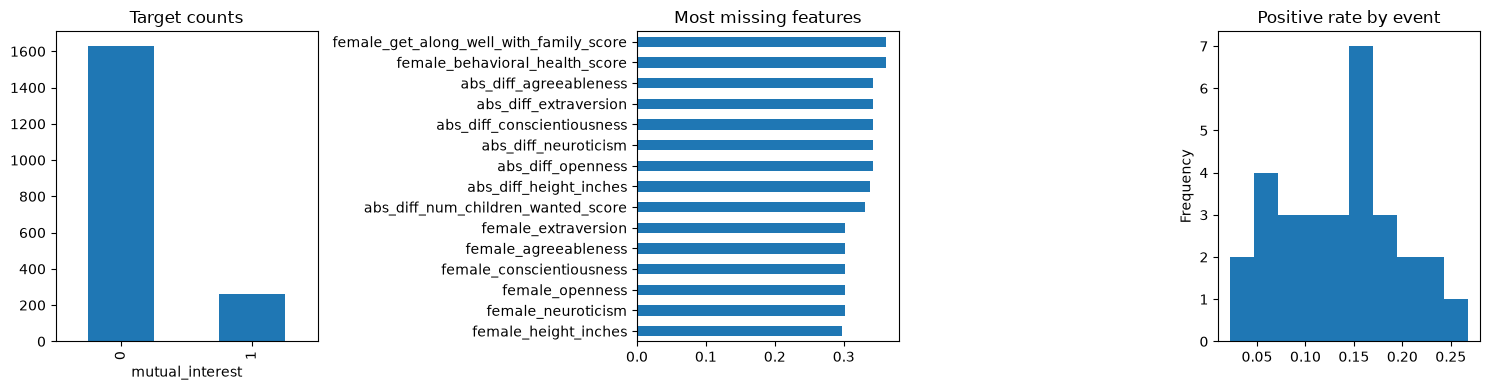

In [3]:
summary = pd.DataFrame({
    'dtype': model_input(frame).dtypes.astype(str),
    'missing_fraction': model_input(frame).isna().mean(),
    'minimum': model_input(frame).min(),
    'median': model_input(frame).median(),
    'maximum': model_input(frame).max(),
}).sort_values('missing_fraction', ascending=False)
display(summary)
display(frame.groupby('mutual_interest')[['male_age', 'female_age', 'abs_diff_age']].median())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
frame.mutual_interest.value_counts().sort_index().plot.bar(ax=axes[0], title='Target counts')
summary.missing_fraction.head(15).sort_values().plot.barh(ax=axes[1], title='Most missing features')
frame.groupby('event_id').mutual_interest.mean().plot.hist(ax=axes[2], bins=10, title='Positive rate by event')
plt.tight_layout()
plt.show()

In [4]:
age_bins = pd.cut(frame.abs_diff_age, bins=[-0.1, 2, 5, 10, 100], labels=['0-2', '3-5', '6-10', '11+'])
age_analysis = frame.groupby(age_bins, observed=True).mutual_interest.agg(['mean', 'size'])
display(age_analysis)
print('Profiles represented in interactions:', len(set(frame.male_user_id) | set(frame.female_user_id)))

,mean,size
abs_diff_age,,
0-2,0.142497,793
3-5,0.152012,671
6-10,0.112022,366
11+,0.051724,58


Profiles represented in interactions: 409


## Validation design and model comparison

The same participants can appear in several dates. We hold out whole **events**, remove participant IDs from features, and use five-fold event-grouped out-of-fold predictions on the development events to choose hyperparameters. This tests transfer to other events more honestly than a random row split, though a participant may still occur in more than one event.

**Primary metric:** average precision (AP), because positives are relatively uncommon. We also report ROC AUC, precision, recall, and a confusion table. A dummy prior model establishes a baseline. Logistic regression, decision trees, and random forests are tuned over small, documented grids.


In [5]:
train_frame, val_frame, test_frame = split_by_event(frame)
display(pd.DataFrame(split_summary(train_frame, val_frame, test_frame)).T)
development = pd.concat([train_frame, val_frame], ignore_index=True)
comparison = compare_models(development)
display(comparison[['model', 'parameters', 'average_precision', 'roc_auc']])

,rows,events,positives,positive_rate
train,1182.0,18.0,145.0,0.122673
validation,338.0,6.0,53.0,0.156805
test,368.0,6.0,61.0,0.165761


,model,parameters,average_precision,roc_auc
0,random_forest,"{'max_depth': None, 'min_samples_leaf': 15}",0.179788,0.569639
1,random_forest,"{'max_depth': 8, 'min_samples_leaf': 15}",0.177882,0.566976
2,random_forest,"{'max_depth': 4, 'min_samples_leaf': 15}",0.169554,0.558853
3,logistic_regression,{'C': 0.01},0.168377,0.575355
4,random_forest,"{'max_depth': None, 'min_samples_leaf': 5}",0.161345,0.557668
5,logistic_regression,{'C': 0.1},0.159699,0.571313
6,logistic_regression,{'C': 1.0},0.155341,0.564325
7,random_forest,"{'max_depth': 8, 'min_samples_leaf': 5}",0.152905,0.557852
8,logistic_regression,{'C': 10.0},0.152755,0.562125
9,random_forest,"{'max_depth': 4, 'min_samples_leaf': 5}",0.147233,0.546030


## Feature importance on held-out development events

Permutation importance measures how much validation AP changes when a feature is shuffled. Correlated features can share importance, and importance does not imply a causal effect. This diagnostic uses only the development split, leaving the final test events untouched.


,feature,ap_change_mean,ap_change_std
13,female_avg_physical_attractiveness_rating,0.034452,0.026517
2,male_avg_physical_attractiveness_rating,0.021064,0.009201
21,female_num_children_wanted_score,0.007763,0.015988
19,female_behavioral_health_score,0.006305,0.019888
20,female_get_along_well_with_family_score,0.006120,0.015533
5,male_extraversion,0.003586,0.019544
12,female_height_inches,0.003077,0.013077
7,male_openness,0.002648,0.005216
25,abs_diff_conscientiousness,0.001450,0.003189
27,abs_diff_neuroticism,0.000802,0.001691


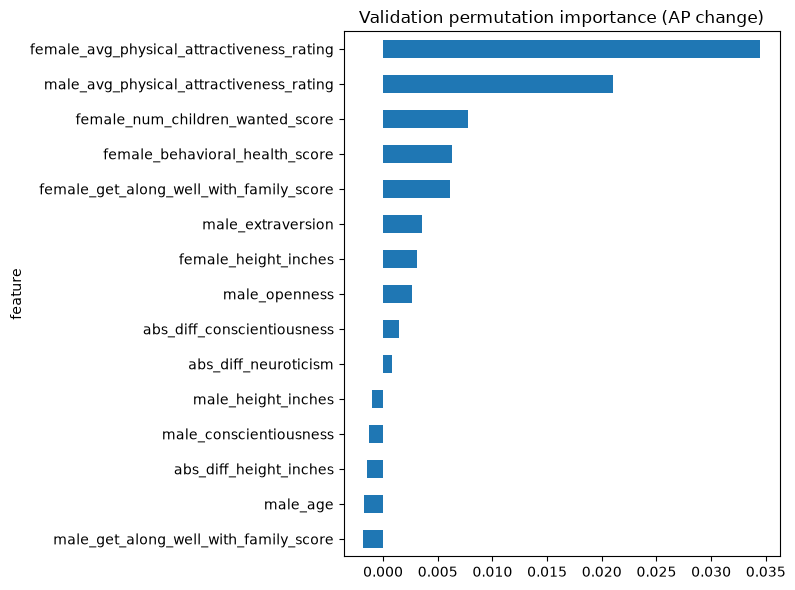

In [6]:
best = comparison.iloc[0]
diagnostic_model = make_model(best['model'], best['parameters'])
diagnostic_model.fit(model_input(train_frame), train_frame.mutual_interest)
importance = permutation_importance(
    diagnostic_model,
    model_input(val_frame),
    val_frame.mutual_interest,
    scoring='average_precision',
    n_repeats=3,
    random_state=42,
)
importance_table = pd.DataFrame({
    'feature': FEATURE_COLUMNS,
    'ap_change_mean': importance.importances_mean,
    'ap_change_std': importance.importances_std,
}).sort_values('ap_change_mean', ascending=False)
display(importance_table.head(15))
importance_table.head(15).sort_values('ap_change_mean').plot.barh(
    x='feature', y='ap_change_mean', legend=False, figsize=(8, 6),
    title='Validation permutation importance (AP change)'
)
plt.tight_layout()
plt.show()

## Final training and untouched test evaluation

`train.py` uses the same code as this notebook: choose the model using grouped development predictions, choose an F1 threshold on those predictions, refit on all development rows, and evaluate once on held-out test events. A weak held-out result is reported as a limitation rather than hidden by selecting a different test split.


In [7]:
report = run_training(DATA_DIR, Path('model.bin'), Path('results/metrics.json'))
display(pd.DataFrame({
    'development_out_of_fold': report['validation'],
    'held_out_test': report['test'],
}).T)
print('Selected model:', report['selected_model'], report['selected_parameters'])
print('Decision threshold:', report['threshold'])
print('Model saved:', Path('model.bin').resolve())

,roc_auc,average_precision,precision,recall,tn,fp,fn,tp
development_out_of_fold,0.569639,0.179788,0.141395,0.767677,399.0,923.0,46.0,152.0
held_out_test,0.490255,0.167393,0.151786,0.557377,117.0,190.0,27.0,34.0


Selected model: random_forest {'max_depth': None, 'min_samples_leaf': 15}
Decision threshold: 0.1
Model saved: model.bin


## Conclusions and limits

Interpret the held-out test metrics against the positive-class prevalence and dummy baseline. If ROC AUC is near 0.5, this feature set is not reliably ranking mutually interested pairs across events. The project still demonstrates the full modeling and deployment workflow; it must not claim useful matchmaking performance without stronger evidence.

The interaction sample is modest, many optional questionnaire fields are missing, and different events may have different populations. The source records in-person eight-minute dates, not online swipe outcomes. This project deliberately excludes ethnicity, religion, politics, income, drug use, and sexual-history fields. The trained API accepts the two profiles and returns a probability plus a thresholded decision.
